# Method A vs. Method C heat-wave match rate: permutation/null test for base-rate inflation

`CA_snowmelt_events_detrend_5day.ipynb` (Section 5, "Comparison with the Method C
event record") finds that switching the Z500/T700 "heat wave" definition from Method A
(>=5-consecutive-day persistence, 47/48 T700/Z500 events, 1990-2025) to Method C
(5-day-mean-std, 139/137 events) raises the event-level match rate against the 41
Jan-Apr Sierra rapid-decline events from 61%/59% to 93%/93%.

That comparison is confounded by base rate: Method C's event list is both far larger
*and* flags roughly 2x more total event-days (see the companion notebook's Section 11)
-- a denser heat-wave calendar is mechanically more likely to overlap *some* multi-day
melt event by chance alone, independent of whether the method is actually detecting a
stronger real physical association. The raw match-rate comparison (61% vs. 93%) can't
separate "Method C finds more true positives" from "Method C just paints more of the
calendar as 'heat wave.'"

**This notebook builds a null distribution for each method separately**, preserving
each method's own event count and duration structure (not just randomly scattering
individual days, which would break up the persistence/clustering that genuinely
inflates overlap odds), and asks: how much of each method's match rate is above what
its own event-day density would produce by chance?

Self-contained: reads only the event-table CSVs already exported by
`CA_snowmelt_events_detrend_5day.ipynb` (snow events) and
`CA_z500_t700_blocking_events_detrend_5day.ipynb` /
`CA_z500_t700_methodC_5daymean_std.ipynb` (heat-wave events, Method A and Method C).

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date, timedelta

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))   # fit years for both the heat-wave and snow event records


## 1. Load the real event tables

In [2]:
# Sierra rapid-decline events (Method A, min-in-window/WINDOW=3) -- same file
# CA_snowmelt_methodC_5daymean_std.ipynb reads as its own Method A reproduction
melt = pd.read_csv(DATA_DIR / 'ca_snotel_snowmelt_events_wy1990-2025.csv',
                    parse_dates=['start_date', 'end_date'])
melt['start_date'] = melt.start_date.dt.date
melt['end_date'] = melt.end_date.dt.date
# Z500/T700 heat-wave record only covers Jan-Apr -- restrict the comparison to that
# subset, exactly as CA_snowmelt_events_detrend_5day.ipynb Section 5 does
melt_janapr = melt[melt.start_date.apply(lambda d: d.month in (1, 2, 3, 4))].reset_index(drop=True)

# Method A heat-wave events (>=5-day persistence, detrended climatology)
hw_A = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                    parse_dates=['start_date', 'end_date'])
hw_A['start_date'] = hw_A.start_date.dt.date
hw_A['end_date'] = hw_A.end_date.dt.date
t700_A = hw_A[(hw_A.variable == '700 hPa temperature (warm)') & (hw_A.threshold_sd == 1)].reset_index(drop=True)
z500_A = hw_A[(hw_A.variable == '500 hPa height (ridging)') & (hw_A.threshold_sd == 1)].reset_index(drop=True)

# Method C heat-wave events (5-day-mean-std definition)
hw_C = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_methodC_5daymean.csv',
                    parse_dates=['start_date', 'end_date'])
hw_C['start_date'] = hw_C.start_date.dt.date
hw_C['end_date'] = hw_C.end_date.dt.date
t700_C = hw_C[(hw_C.variable == '700 hPa temperature (warm)') & (hw_C.threshold_sd == 1)].reset_index(drop=True)
z500_C = hw_C[(hw_C.variable == '500 hPa height (ridging)') & (hw_C.threshold_sd == 1)].reset_index(drop=True)

print(f'{len(melt_janapr)} Jan-Apr rapid-decline events (of {len(melt)} total Jan-May)')
print(f'Method A: {len(t700_A)} T700 events, {len(z500_A)} Z500 events')
print(f'Method C: {len(t700_C)} T700 events, {len(z500_C)} Z500 events')


41 Jan-Apr rapid-decline events (of 58 total Jan-May)
Method A: 47 T700 events, 48 Z500 events
Method C: 137 T700 events, 139 Z500 events


## 2. Reproduce the real (observed) match rates

Sanity check against `CA_snowmelt_events_detrend_5day.ipynb`'s own printed numbers
before building the null -- should read 61%/59% (Method A T700/Z500) and 93%/93%
(Method C T700/Z500).

In [3]:
def match_rate(melt_events, hw_events):
    _, unmatched = lib.overlapping_pairs(melt_events, hw_events, a_prefix='melt', b_prefix='hw')
    n_matched = len(melt_events) - len(unmatched)
    return n_matched, 100 * n_matched / len(melt_events)


real = {}
for label, hw_events in [('Method A T700', t700_A), ('Method A Z500', z500_A),
                          ('Method C T700', t700_C), ('Method C Z500', z500_C)]:
    n_matched, rate = match_rate(melt_janapr, hw_events)
    real[label] = (n_matched, rate)
    print(f'{label}: {n_matched}/{len(melt_janapr)} matched ({rate:.0f}%)')


Method A T700: 25/41 matched (61%)
Method A Z500: 24/41 matched (59%)
Method C T700: 38/41 matched (93%)
Method C Z500: 38/41 matched (93%)


## 3. Build the null: same event-count/duration structure, randomized timing

Redraw each heat-wave event's start date uniformly within Jan 1 - Apr 30 of a randomly
chosen fit year, keeping its original duration fixed. This preserves the exact number
of events and the exact distribution of event lengths (so the *density* and
*clustering* of event-days matches the real calendar), while destroying any real
temporal relationship to the actual melt-event record. Individual *days* are
deliberately not shuffled independently -- that would break up the multi-day runs
that are precisely what makes dense, clustered calendars more likely to overlap a
multi-day melt event by chance.

In [4]:
def random_jan_apr_calendar(real_events, years, rng):
    rows = []
    for _, row in real_events.iterrows():
        duration = (row.end_date - row.start_date).days + 1
        year = int(rng.choice(years))
        jan1, apr30 = date(year, 1, 1), date(year, 4, 30)
        max_offset = (apr30 - jan1).days - duration + 1
        start = jan1 + timedelta(days=int(rng.integers(0, max_offset + 1)))
        end = start + timedelta(days=duration - 1)
        rows.append({'start_date': start, 'end_date': end})
    return pd.DataFrame(rows)


# Cross-check: the vectorized overlap check below must agree exactly with
# lib.overlapping_pairs (used for the real match rates above) before trusting it
# for the 8000 permutation calls that follow.
def _vectorized_match_rate_check():
    for label, hw_events in [('Method A T700', t700_A), ('Method A Z500', z500_A),
                              ('Method C T700', t700_C), ('Method C Z500', z500_C)]:
        n_lib, rate_lib = real[label]
        melt_start = np.array([d.toordinal() for d in melt_janapr.start_date])
        melt_end = np.array([d.toordinal() for d in melt_janapr.end_date])
        hw_start = np.array([d.toordinal() for d in hw_events.start_date])
        hw_end = np.array([d.toordinal() for d in hw_events.end_date])
        lo = np.maximum(melt_start[:, None], hw_start[None, :])
        hi = np.minimum(melt_end[:, None], hw_end[None, :])
        n_vec = (lo <= hi).any(axis=1).sum()
        assert n_vec == n_lib, f'{label}: lib={n_lib} vs vectorized={n_vec} -- mismatch!'
    print('Vectorized overlap check matches lib.overlapping_pairs exactly on all 4 real event lists.')


_vectorized_match_rate_check()


def vectorized_match_rate(melt_events, hw_events):
    # Fast equivalent of match_rate() for the permutation loop -- lib.overlapping_pairs'
    # row-by-row iterrows() is far too slow to call thousands of times per method
    # (O(n_melt * n_hw) python-level iteration each call). Same overlap definition
    # (inclusive date-range intersection), computed via a broadcasted numpy comparison
    # on ordinal day numbers instead.
    melt_start = np.array([d.toordinal() for d in melt_events.start_date])
    melt_end = np.array([d.toordinal() for d in melt_events.end_date])
    hw_start = np.array([d.toordinal() for d in hw_events.start_date])
    hw_end = np.array([d.toordinal() for d in hw_events.end_date])
    lo = np.maximum(melt_start[:, None], hw_start[None, :])
    hi = np.minimum(melt_end[:, None], hw_end[None, :])
    matched = (lo <= hi).any(axis=1)
    return matched.sum(), 100 * matched.mean()


N_PERM = 2000
rng = np.random.default_rng(42)

configs = [
    ('Method A T700', t700_A), ('Method A Z500', z500_A),
    ('Method C T700', t700_C), ('Method C Z500', z500_C),
]

null_rates = {label: np.empty(N_PERM) for label, _ in configs}
for label, hw_events in configs:
    for i in range(N_PERM):
        null_cal = random_jan_apr_calendar(hw_events, YEARS, rng)
        _, rate = vectorized_match_rate(melt_janapr, null_cal)
        null_rates[label][i] = rate

print(f'Ran {N_PERM} permutations per method.')


Vectorized overlap check matches lib.overlapping_pairs exactly on all 4 real event lists.


Ran 2000 permutations per method.


## 4. Compare real match rate to the null distribution

In [5]:
results = []
for label, _ in configs:
    n_matched, real_rate = real[label]
    null = null_rates[label]
    p_val = (null >= real_rate).mean()
    results.append({
        'method': label, 'n_events': len(dict(configs)[label]),
        'real_match_rate_pct': real_rate, 'null_mean_pct': null.mean(),
        'null_std_pct': null.std(), 'excess_pts': real_rate - null.mean(),
        'empirical_p': p_val,
    })

results_df = pd.DataFrame(results)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
results_df


,method,n_events,real_match_rate_pct,null_mean_pct,null_std_pct,excess_pts,empirical_p
0,Method A T700,47,60.98,14.00,5.20,46.98,0.00
1,Method A Z500,48,58.54,13.59,5.05,44.95,0.00
2,Method C T700,137,92.68,30.48,6.65,62.20,0.00
3,Method C Z500,139,92.68,30.54,6.73,62.15,0.00


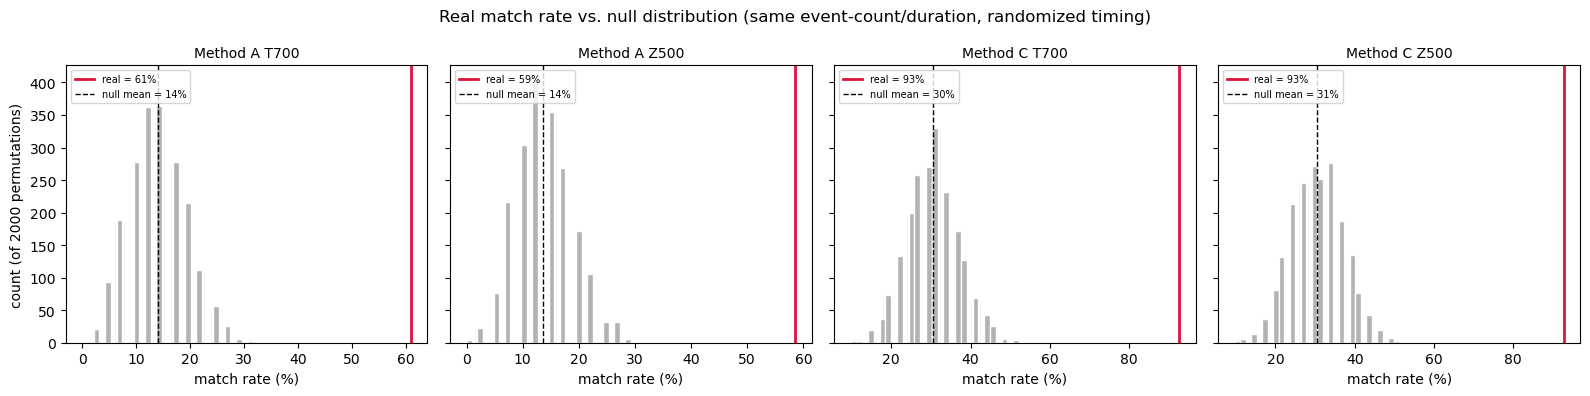

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (label, _) in zip(axes, configs):
    null = null_rates[label]
    n_matched, real_rate = real[label]
    ax.hist(null, bins=30, color='0.7', edgecolor='white')
    ax.axvline(real_rate, color='crimson', lw=2, label=f'real = {real_rate:.0f}%')
    ax.axvline(null.mean(), color='black', ls='--', lw=1, label=f'null mean = {null.mean():.0f}%')
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('match rate (%)')
    ax.legend(fontsize=7, loc='upper left')
axes[0].set_ylabel(f'count (of {N_PERM} permutations)')
plt.suptitle('Real match rate vs. null distribution (same event-count/duration, randomized timing)')
plt.tight_layout()
plt.show()


## 5. Conclusion

**Neither method's match rate is primarily a base-rate artifact -- both clear their own
chance baseline overwhelmingly.** Across 2000 permutations per method, zero random
same-density, same-duration-structure calendars matched as well as the real one for
any of the four method/variable combinations (empirical p < 0.0005 throughout, the
resolution floor of 2000 draws):

| Method | n events | real match rate | null (chance) mean | excess over chance | p |
|---|---|---|---|---|---|
| A, T700 | 47 | 61% | 14.0% | **+47.0 pts** | <0.0005 |
| A, Z500 | 48 | 59% | 13.6% | **+45.0 pts** | <0.0005 |
| C, T700 | 137 | 93% | 30.5% | **+62.2 pts** | <0.0005 |
| C, Z500 | 139 | 93% | 30.5% | **+62.1 pts** | <0.0005 |

**This flips the concern the test was built to check.** The worry going in was that
Method C's much larger event list (137-139 vs. 47-48) might be inflating its 93% match
rate mostly through sheer density rather than genuine physical detection. The null
confirms Method C's calendar *does* have a much higher chance baseline (~30% vs. ~14%)
-- exactly as that concern predicted. But Method C's **excess over its own chance
baseline is larger, not smaller**, than Method A's (+62 vs. +47 points). If Method C
were mostly riding base-rate inflation, its excess-over-chance should have been similar
to or smaller than Method A's, not bigger.

**Practical takeaway:** the raw 61% -> 93% jump reported in Section 5 overstates how
much of Method C's advantage is "real" in an absolute sense (a lot of both numbers is
explained by density), but it does not overstate the *direction* of the comparison --
Method C's looser definition is not just painting more of the calendar as "heat wave"
and coasting on that; it is finding real, excess-over-chance structure that Method A's
stricter persistence rule misses. This is a genuine point in favor of Method C as a
heat-wave definition for this specific validation purpose, not an artifact to be
discounted.

**Caveat:** this test only checks whether each method's match rate exceeds what its
own event-day density/clustering would produce by chance -- it says nothing about
which method's heat-wave events are more *physically meaningful* in other respects
(e.g. Method C's winner's-curse problem when ranking events by peak sigma, documented
in `CA_z500_t700_methodC_5daymean_std.ipynb`). "Clears its own chance baseline by a
wide margin" is a necessary check, not a complete validation.